# June 2019 event -- full artifact parity with `main_actual_data_pipeline.ipynb`

Reproduces EVERY artifact the original October-anchored `main_actual_data_pipeline.
ipynb` produced (observation plot, backward-trajectory demo + animations, multi-
member demo + animation, Monte Carlo density vs. KDE, T18-T26 forward validation +
final top-10 table/JSON), now for the corrected June 2019 event -- same filenames,
saved under `result/` instead of `results/actual_data/` (which is left untouched).

Reuses the ALREADY-COMPUTED June 2019 Stage III particle history
(`result/stage3_particle_history_june2019.npz`, from `T_june2019_stage3_run.ipynb`)
-- Stage III backward transport is NOT rerun here. No algorithm/equation/weight is
changed anywhere in this notebook; every computation calls the same existing,
unmodified `iste/` functions the original notebook used.

**Task 4 addition:** a researcher-facing DISPLAY-ONLY color normalization for the
Support/KDE heatmap panels and the backtracking animations -- see the dedicated
markdown note before Section 5b below. It changes ONLY how values are mapped to
color; every underlying `support_grids_by_t_s`/candidate/score value is untouched.

In [1]:
import os, sys, json, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap, PowerNorm
import numpy as np

from iste.observation import adapt_upstream_particles
from iste.environment import load_field_dataset
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import EnsembleRunRecords
from iste.particle_query import query_particle_slice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.forward_budget import ForwardBudgetConfig
from iste.forward_accuracy import ComparisonConfig
from iste.candidate_screening import ScreeningConfig
from iste.phase2_pipeline import Phase2RunConfig, run_phase2_pipeline, save_phase2_artifact

RESULTS_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"outputs will be saved under {RESULTS_DIR}")

def save_with_retry(save_callable, label="", retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            save_callable()
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {label}: {e}")
            time.sleep(delay)
    raise last_err

def save_animation_with_retry(anim, mp4_path, gif_path, fps, retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            anim.save(mp4_path, writer="ffmpeg", fps=fps, dpi=100)
            print(f"saved animation (MP4) to {mp4_path}")
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {mp4_path}: {e}")
            time.sleep(delay)
        except Exception as e:
            anim.save(gif_path, writer="pillow", fps=fps)
            print(f"ffmpeg unavailable ({e}); saved GIF to {gif_path}")
            return
    anim.save(gif_path, writer="pillow", fps=fps)
    print(f"MP4 save kept failing transiently ({last_err}); saved GIF to {gif_path} instead")

def write_json_with_retry(path, obj, label=""):
    def _do():
        with open(path, "w", encoding="utf-8") as f:
            json.dump(obj, f, indent=2)
    save_with_retry(_do, label=label or os.path.basename(path))

outputs will be saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result


## 1. Real observation (`ow-0008.jpg`) -- true June 2019 timestamp

In [2]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
assert spill["total_parcels"] == 548 == len(spill["parcels"])

TRUE_OBS_TIMESTAMP = np.datetime64(spill["timestamp"], "ns")
print(f"image_filename : {spill['image_filename']}")
print(f"TRUE timestamp : {TRUE_OBS_TIMESTAMP}")
print(f"total_parcels  : {spill['total_parcels']}")

write_json_with_retry(os.path.join(RESULTS_DIR, "observation_summary.json"), {
    "image_filename": spill["image_filename"], "mask_filename": spill["mask_filename"],
    "true_timestamp": spill["timestamp"], "area_pixels": spill["area_pixels"],
    "bounding_box": spill["bounding_box"], "total_parcels": spill["total_parcels"],
})
print("saved observation_summary.json")

image_filename : ow-0008.jpg
TRUE timestamp : 2019-06-14T20:35:58.000000000
total_parcels  : 548
saved observation_summary.json


### Observation visualization

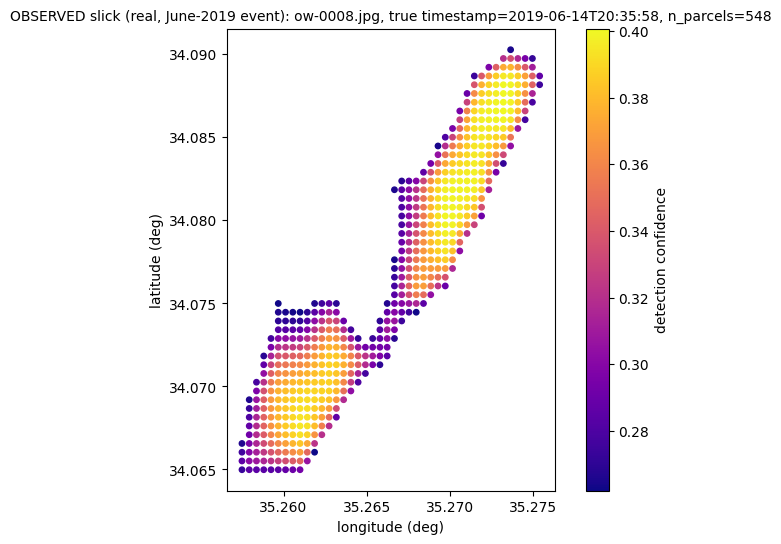

In [3]:
parcels = spill["parcels"]
obs_lat = np.array([p["lat"] for p in parcels])
obs_lon = np.array([p["lon"] for p in parcels])
obs_conf = np.array([p["confidence"] for p in parcels])

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(obs_lon, obs_lat, c=obs_conf, s=15, cmap="plasma")
fig.colorbar(sc, ax=ax, label="detection confidence")
ax.set_title(f"OBSERVED slick (real, June-2019 event): {spill['image_filename']}, true timestamp={spill['timestamp']}, n_parcels={spill['total_parcels']}", fontsize=10)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)"); ax.set_aspect("equal")
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "01_observation.png"), dpi=110), label="01_observation.png")
plt.show()

## 2. Load the ALREADY-COMPUTED June 2019 Stage III result (not rerun here)

In [4]:
history_path = os.path.join(RESULTS_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)
def _none_if_empty(arr):
    return None if arr.size == 0 else arr
records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
RUN_T_OBS = np.datetime64(np.max(records.timestamp), "ns")
assert RUN_T_OBS == TRUE_OBS_TIMESTAMP, (RUN_T_OBS, TRUE_OBS_TIMESTAMP)
checkpoints = np.unique(records.timestamp)
print(f"loaded {records.n_records} June-2019 real rows; {len(checkpoints)} checkpoints; RUN_T_OBS={RUN_T_OBS} (TRUE observation, no workaround needed)")

particle_records_for_adapt = [
    {
        "particle_id": str(p["id"]), "latitude": p["lat"], "longitude": p["lon"],
        "observation_pixel_id": str(p["id"]), "timestamp": RUN_T_OBS,
    }
    for p in parcels
]
adapted = adapt_upstream_particles(particle_records_for_adapt)
assert adapted.n_particles == 548

loaded 240024 June-2019 real rows; 73 checkpoints; RUN_T_OBS=2019-06-14T20:35:58.000000000 (TRUE observation, no workaround needed)


In [5]:
CROPPED_OCEAN_PATH = os.path.join(RESULTS_DIR, "ocean_june2019_region.nc")
ocean = load_field_dataset(CROPPED_OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="lat", lon_dim="lon")
print(f"ocean (cropped June-2019): grid {ocean.lat.shape} x {ocean.lon.shape}, time {ocean.time[0]} .. {ocean.time[-1]}")

FULL_ENSEMBLE_N_MEMBERS_CONFIGURED = 50
FORCING_MEMBER_IDS_USED = (0, 1, 2, 3, 4, 5)
ensemble_config = ForcingEnsembleConfig(n_members=FULL_ENSEMBLE_N_MEMBERS_CONFIGURED, master_seed=7)
ensemble = ForcingEnsemble(ocean, ensemble_config)
K_DIFFUSIVITY = 3.0
K = np.full((len(ocean.lat), len(ocean.lon)), K_DIFFUSIVITY)

# --- Real geographic basemap (Task 2), zoomed to the actual trajectory (Task 3) ---
import cartopy.crs as ccrs
import cartopy.feature as cfeature

AOI_NORTH, AOI_WEST, AOI_SOUTH, AOI_EAST = 36.372, 27.121, 30.1875, 36.088  # project AOI (reference)
MAP_PROJECTION = ccrs.PlateCarree()

TRAJ_LAT_MIN = float(records.lat[records.valid].min())
TRAJ_LAT_MAX = float(records.lat[records.valid].max())
TRAJ_LON_MIN = float(records.lon[records.valid].min())
TRAJ_LON_MAX = float(records.lon[records.valid].max())
print(f"complete backtracked-trajectory bbox: lat [{TRAJ_LAT_MIN:.5f}, {TRAJ_LAT_MAX:.5f}] "
      f"(span {TRAJ_LAT_MAX-TRAJ_LAT_MIN:.4f} deg), lon [{TRAJ_LON_MIN:.5f}, {TRAJ_LON_MAX:.5f}] "
      f"(span {TRAJ_LON_MAX-TRAJ_LON_MIN:.4f} deg)")

TRAJECTORY_MAP_MARGIN_DEG = 0.08  # explicit, configurable (Task 3 requirement 8)
ZOOM_WEST = TRAJ_LON_MIN - TRAJECTORY_MAP_MARGIN_DEG
ZOOM_EAST = TRAJ_LON_MAX + TRAJECTORY_MAP_MARGIN_DEG
ZOOM_SOUTH = TRAJ_LAT_MIN - TRAJECTORY_MAP_MARGIN_DEG
ZOOM_NORTH = TRAJ_LAT_MAX + TRAJECTORY_MAP_MARGIN_DEG
ANIMATION_EXTENT = (ZOOM_WEST, ZOOM_EAST, ZOOM_SOUTH, ZOOM_NORTH)
print(f"animation map extent (trajectory bbox + {TRAJECTORY_MAP_MARGIN_DEG} deg margin): "
      f"lon [{ZOOM_WEST:.4f}, {ZOOM_EAST:.4f}], lat [{ZOOM_SOUTH:.4f}, {ZOOM_NORTH:.4f}]")

_land_10m = cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8")
_ocean_10m = cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3")

def add_geographic_basemap(ax, extent):
    """Real Natural Earth (10m) coastline/land/ocean/border basemap, fixed to `extent`.
    Added ONCE per Axes; FuncAnimation's update() below never touches the Axes extent
    or re-adds features, so the background (and zoom level) is identical every frame."""
    west, east, south, north = extent
    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    ax.add_feature(_ocean_10m, zorder=0)
    ax.add_feature(_land_10m, zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.5, linestyle=":", zorder=2)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}
    return ax

print(f"geographic basemap: cartopy {__import__('cartopy').__version__}, Natural Earth 10m, PlateCarree")

C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

ocean (cropped June-2019): grid (150,) x (218,), time 2019-06-07T00:30:00.000000000 .. 2019-06-14T23:30:00.000000000
complete backtracked-trajectory bbox: lat [34.06498, 34.43411] (span 0.3691 deg), lon [34.91946, 35.32912] (span 0.4097 deg)
animation map extent (trajectory bbox + 0.08 deg margin): lon [34.8395, 35.4091], lat [33.9850, 34.5141]
geographic basemap: cartopy 0.25.0, Natural Earth 10m, PlateCarree


## 3. Historical timestamp processing: T14 -> T15 -> T16 -> T17 (full 3-day sweep, June 2019)

**Moved earlier in this notebook (Task 4):** originally this sweep ran after the
backward-trajectory demo/animations; it now runs first because the animations'
new evolving Support/KDE heatmap layer (Task 4 requirement 9) needs
`support_grids_by_t_s` already computed. This is a pure notebook REORDERING -- the
exact same `iste.*` calls, same formulas, same values as before; nothing scientific
changed.

In [6]:
historical_timestamps = checkpoints[checkpoints != RUN_T_OBS]
print(f"historical timestamp grid: {len(historical_timestamps)} timestamps")

obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

all_candidates = []
support_grids_by_t_s = {}
t0 = time.time()
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    support_grids_by_t_s[float(t_s)] = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    candidates = find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config)
    all_candidates.extend(candidates)

# also compute T0's own support grid (historical_timestamps excludes T0/RUN_T_OBS by
# construction) -- Task 4 requirement 7/9 needs a T0 frame too.
_t0_slice = query_particle_slice(records, RUN_T_OBS)
_t0_index = build_particle_neighborhood_index(_t0_slice)
_t0_support_map = compute_support_map(_t0_index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
support_grids_by_t_s[float(RUN_T_OBS)] = np.array([sf.support for sf in _t0_support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
t1 = time.time()
print(f"T14-T17 sweep over {len(historical_timestamps)} historical timestamps + T0 took {t1 - t0:.1f}s")
print(f"TOTAL real hotspots/candidates found: {len(all_candidates)}; support_grids_by_t_s now has {len(support_grids_by_t_s)} entries (T0..T72)")

hotspots_export = [
    {"candidate_id": c.candidate_id, "lat": c.y_peak, "lon": c.x_peak,
     "t_s": str(np.datetime_as_string(np.datetime64(c.t_s, "ns"), unit="s")),
     "support_score": c.support_score, "density_score": c.density_score,
     "weighted_support_score": c.weighted_support_score, "pixel_diversity_score": c.pixel_diversity_score}
    for c in all_candidates
]
write_json_with_retry(os.path.join(RESULTS_DIR, "hotspots.json"), hotspots_export, label="hotspots.json")
print(f"saved hotspots.json ({len(hotspots_export)} entries)")

historical timestamp grid: 72 timestamps


T14-T17 sweep over 72 historical timestamps + T0 took 155.5s
TOTAL real hotspots/candidates found: 271; support_grids_by_t_s now has 73 entries (T0..T72)
saved hotspots.json (271 entries)


## Task 4 -- researcher-facing display normalization for Support/KDE heatmaps

**Inspection (requirement 1), on the real June-2019 candidate set:** the 271
candidate PEAK `support_score` values are heavily right-skewed --
`skewness ~= 2.13`; percentiles `1%=2.98, 5%=3.01, 25%=3.18, 50%(median)=6.12,
75%=979.7, 95%=3485.6, 99%=4565.9`, `max=4735.7`. The full T16 support GRID (every
cell, not just peaks) is even more skewed -- mostly near-zero background with a
handful of high peaks near `t_obs`. Under a plain LINEAR color map with one shared
`vmax` (the pre-Task-4 behaviour), almost every timestamp except the 1-2 closest to
`t_obs` renders as visually near-black, exactly the reported problem.

**Fix -- display layer ONLY (requirement 2):** `matplotlib.colors.PowerNorm`
(`gamma=0.4`, i.e. a fixed square-root-like stretch), applied with a SINGLE GLOBAL
`vmax` = the maximum raw Support value across ALL T0-T72 grids combined --
the SAME transform and the SAME reference for every single timestamp. The
underlying `support_grids_by_t_s` arrays, every candidate's `support_score`, and
every T29-T39 value are never touched, never re-saved, and never re-read by any
score/ranking/clustering/uncertainty computation -- this cell only changes which
COLOR a given number is drawn as.

**Why this is NOT per-frame min-max normalization (requirement 4, explicitly
excluded):** per-frame min-max would rescale EACH timestamp's own weak peak to look
just as "hot" as a genuinely strong timestamp's peak -- destroying true relative-
intensity comparison between times. Here, one FIXED `(gamma, vmax)` pair is reused
unchanged at every timestamp: a cell with raw Support=200 always renders lighter
than a cell with raw Support=100, at every single timestamp, exactly as it would
under the original linear scale -- only WHERE in the color ramp that comparison
becomes visible changes (the low end is stretched, the high end compressed), which
is precisely what makes weak/old structure visible without inventing any new,
timestamp-specific reference. `gamma=1.0` recovers the original plain-linear
behaviour exactly, so this is a strict generalization, not a replacement formula.

In [7]:
DISPLAY_GAMMA = 0.4  # < 1 stretches weak/low values, compresses strong peaks; 1.0 = original linear behaviour. Explicit, configurable.
GLOBAL_SUPPORT_VMAX = max(float(g.max()) for g in support_grids_by_t_s.values())  # ONE fixed reference for every T0-T72 frame -- not per-frame min-max
print(f"display normalization: PowerNorm(gamma={DISPLAY_GAMMA}), fixed vmin=0, fixed vmax={GLOBAL_SUPPORT_VMAX:.1f} "
      f"(global max across all {len(support_grids_by_t_s)} T0-T72 grids)")

def display_norm():
    """A fresh PowerNorm instance per plot call (Normalize objects carry internal
    state and must not be shared across mappables) -- always built from the SAME
    fixed (DISPLAY_GAMMA, GLOBAL_SUPPORT_VMAX) reference, so every call is directly
    comparable to every other."""
    return PowerNorm(gamma=DISPLAY_GAMMA, vmin=0.0, vmax=GLOBAL_SUPPORT_VMAX)

DISPLAY_NORM_COLORBAR_LABEL = (
    f"Display-normalized T16 Support (PowerNorm \u03b3={DISPLAY_GAMMA}, shared fixed "
    f"vmax={GLOBAL_SUPPORT_VMAX:.0f} across all T0-T72 -- color mapping only, NOT the raw value)"
)
RAW_LINEAR_COLORBAR_LABEL = "Raw T16 Support (linear color scale, shared fixed vmax across all T0-T72)"

display normalization: PowerNorm(gamma=0.4), fixed vmin=0, fixed vmax=4735.7 (global max across all 73 T0-T72 grids)


### Before-vs-after: one recent + one old timestamp, raw-linear vs. display-normalized

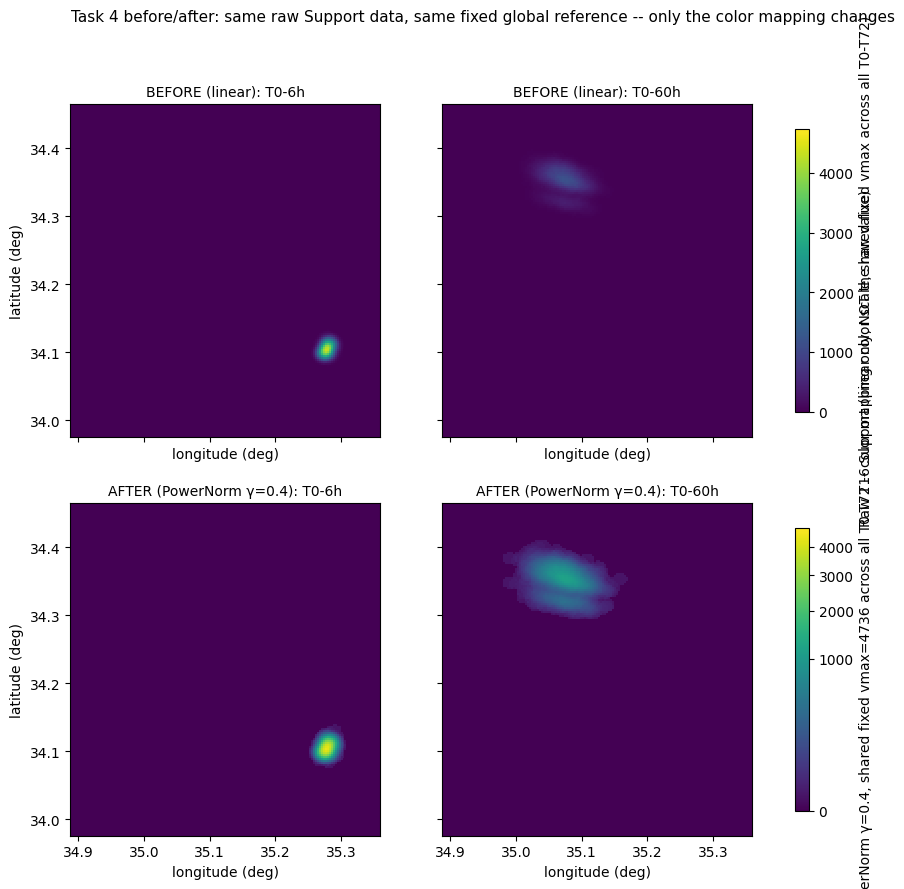

In [8]:
compare_hours = [6, 60]  # one recent, one old -- requirement 11
compare_t_s = [RUN_T_OBS - np.timedelta64(h, "h") for h in compare_hours]

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5), sharex=True, sharey=True)
for col, (h, t_s) in enumerate(zip(compare_hours, compare_t_s)):
    grid_vals = support_grids_by_t_s[float(t_s)]
    mesh_before = axes[0, col].pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", vmin=0, vmax=GLOBAL_SUPPORT_VMAX)
    axes[0, col].set_title(f"BEFORE (linear): T0-{h}h", fontsize=10)
    mesh_after = axes[1, col].pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", norm=display_norm())
    axes[1, col].set_title(f"AFTER (PowerNorm \u03b3={DISPLAY_GAMMA}): T0-{h}h", fontsize=10)
    for row in (0, 1):
        axes[row, col].set_xlabel("longitude (deg)")
axes[0, 0].set_ylabel("latitude (deg)"); axes[1, 0].set_ylabel("latitude (deg)")
fig.colorbar(mesh_before, ax=axes[0, :], label=RAW_LINEAR_COLORBAR_LABEL, shrink=0.85)
fig.colorbar(mesh_after, ax=axes[1, :], label=DISPLAY_NORM_COLORBAR_LABEL, shrink=0.85)
fig.suptitle("Task 4 before/after: same raw Support data, same fixed global reference -- only the color mapping changes", fontsize=11)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "T4_heatmap_before_after.png"), dpi=100), label="T4_heatmap_before_after.png")
plt.show()

## 4. Backward-track 10 real particles (detailed demonstration) -- June 2019

In [9]:
unique_particle_ids = sorted(set(records.particle_id.tolist()), key=lambda x: int(x))
rng = np.random.default_rng(2024)
selected_10 = sorted(rng.choice(unique_particle_ids, size=10, replace=False).tolist(), key=int)
print(f"10 deterministically-selected real particle_ids: {selected_10}")

member0_mask = records.forcing_member_id == 0
traj = {}
for pid in selected_10:
    mask = (records.particle_id == pid) & member0_mask
    order = np.argsort(-records.timestamp[mask].astype("int64"))
    traj[pid] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])
    print(f"  particle_id={pid}: {len(traj[pid]['t'])} checkpoints, t_obs pos=({traj[pid]['lat'][0]:.5f},{traj[pid]['lon'][0]:.5f})")

10 deterministically-selected real particle_ids: ['49', '116', '130', '168', '172', '364', '436', '495', '500', '545']
  particle_id=49: 73 checkpoints, t_obs pos=(34.06709,35.26143)
  particle_id=116: 73 checkpoints, t_obs pos=(34.06973,35.26362)
  particle_id=130: 73 checkpoints, t_obs pos=(34.07025,35.26362)
  particle_id=168: 73 checkpoints, t_obs pos=(34.07183,35.26012)
  particle_id=172: 73 checkpoints, t_obs pos=(34.07183,35.26187)
  particle_id=364: 73 checkpoints, t_obs pos=(34.08079,35.26843)
  particle_id=436: 73 checkpoints, t_obs pos=(34.08395,35.27018)
  particle_id=495: 73 checkpoints, t_obs pos=(34.08712,35.27105)
  particle_id=500: 73 checkpoints, t_obs pos=(34.08712,35.27324)
  particle_id=545: 73 checkpoints, t_obs pos=(34.08975,35.27455)


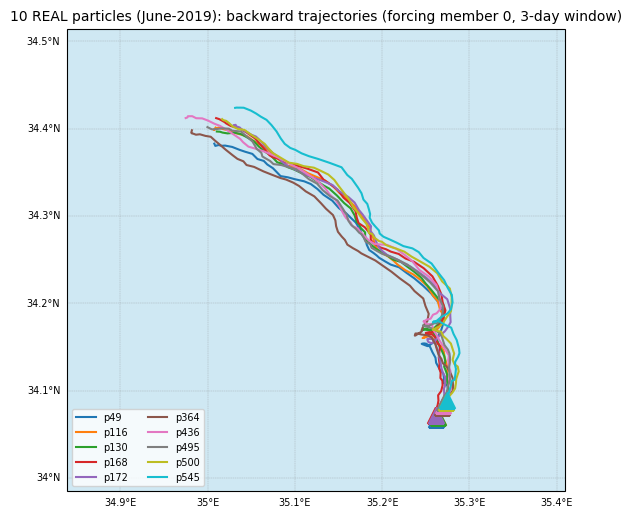

saved demo10_backward_trajectories.npz


In [10]:
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": MAP_PROJECTION})
colors = plt.cm.tab10(np.linspace(0, 1, 10))
add_geographic_basemap(ax, ANIMATION_EXTENT)
for pid, c in zip(selected_10, colors):
    ax.plot(traj[pid]["lon"], traj[pid]["lat"], "-", color=c, linewidth=1.5, label=f"p{pid}", transform=ccrs.PlateCarree(), zorder=5)
    ax.plot(traj[pid]["lon"][0], traj[pid]["lat"][0], "^", color=c, markersize=11, transform=ccrs.PlateCarree(), zorder=6)
ax.set_title("10 REAL particles (June-2019): backward trajectories (forcing member 0, 3-day window)", fontsize=10)
ax.legend(fontsize=7, ncol=2, loc="lower left")
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "02_backward_trajectories_10particles.png"), dpi=110), label="02_backward_trajectories_10particles.png")
plt.show()

save_with_retry(lambda: np.savez_compressed(
    os.path.join(RESULTS_DIR, "demo10_backward_trajectories.npz"),
    particle_ids=np.array(selected_10, dtype=object),
    **{f"lat_{pid}": traj[pid]["lat"] for pid in selected_10},
    **{f"lon_{pid}": traj[pid]["lon"] for pid in selected_10},
    **{f"t_{pid}": traj[pid]["t"] for pid in selected_10},
), label="demo10_backward_trajectories.npz")
print("saved demo10_backward_trajectories.npz")

### Backward-transport animation (10 real particles, June 2019)

**Task 4 requirement 9:** now includes an evolving Support/KDE heatmap layer (the
SAME `display_norm()` fixed-reference color mapping used above) under the particle
trajectories, updated every frame from `support_grids_by_t_s[t_now]` -- the
geographic basemap itself (Task 2/3) stays fixed; only this heatmap layer's DATA
changes per frame, its color scale never does.

In [11]:
fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": MAP_PROJECTION})
add_geographic_basemap(ax, ANIMATION_EXTENT)
_initial_grid = support_grids_by_t_s[float(checkpoints[-1])]  # checkpoints ascending -> [-1] is T0
heatmap_mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, _initial_grid, shading="auto", cmap="viridis", norm=display_norm(), transform=ccrs.PlateCarree(), zorder=3, alpha=0.85)
cb = fig.colorbar(heatmap_mesh, ax=ax, shrink=0.7, pad=0.02)
cb.set_label(DISPLAY_NORM_COLORBAR_LABEL, fontsize=6.5)
lines = [ax.plot([], [], "-", color=c, linewidth=1.8, transform=ccrs.PlateCarree(), zorder=5)[0] for c in colors]
points = [ax.plot([], [], "o", color=c, markersize=10, transform=ccrs.PlateCarree(), zorder=6)[0] for c in colors]
title = ax.set_title("")

def init():
    for l, p in zip(lines, points):
        l.set_data([], []); p.set_data([], [])
    return lines + points + [title, heatmap_mesh]

def update(frame):
    for i, pid in enumerate(selected_10):
        lines[i].set_data(traj[pid]["lon"][:frame + 1], traj[pid]["lat"][:frame + 1])
        points[i].set_data([traj[pid]["lon"][frame]], [traj[pid]["lat"][frame]])
    t_now = traj[selected_10[0]]["t"][frame]
    heatmap_mesh.set_array(support_grids_by_t_s[float(np.datetime64(t_now, "ns"))].ravel())
    title.set_text(f"Backward transport (June-2019 real Stage III, member 0) -- t = {np.datetime64(t_now,'ns')}")
    return lines + points + [title, heatmap_mesh]

n_frames = len(checkpoints)
anim = animation.FuncAnimation(fig, update, frames=n_frames, init_func=init, blit=False, interval=200)
mp4_path = os.path.join(RESULTS_DIR, "03_backward_animation.mp4")
gif_path = os.path.join(RESULTS_DIR, "03_backward_animation.gif")
save_animation_with_retry(anim, mp4_path, gif_path, fps=6)
plt.close(fig)

saved animation (MP4) to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\03_backward_animation.mp4


## 5. The same 10 real particles under multiple forcing members (June 2019)

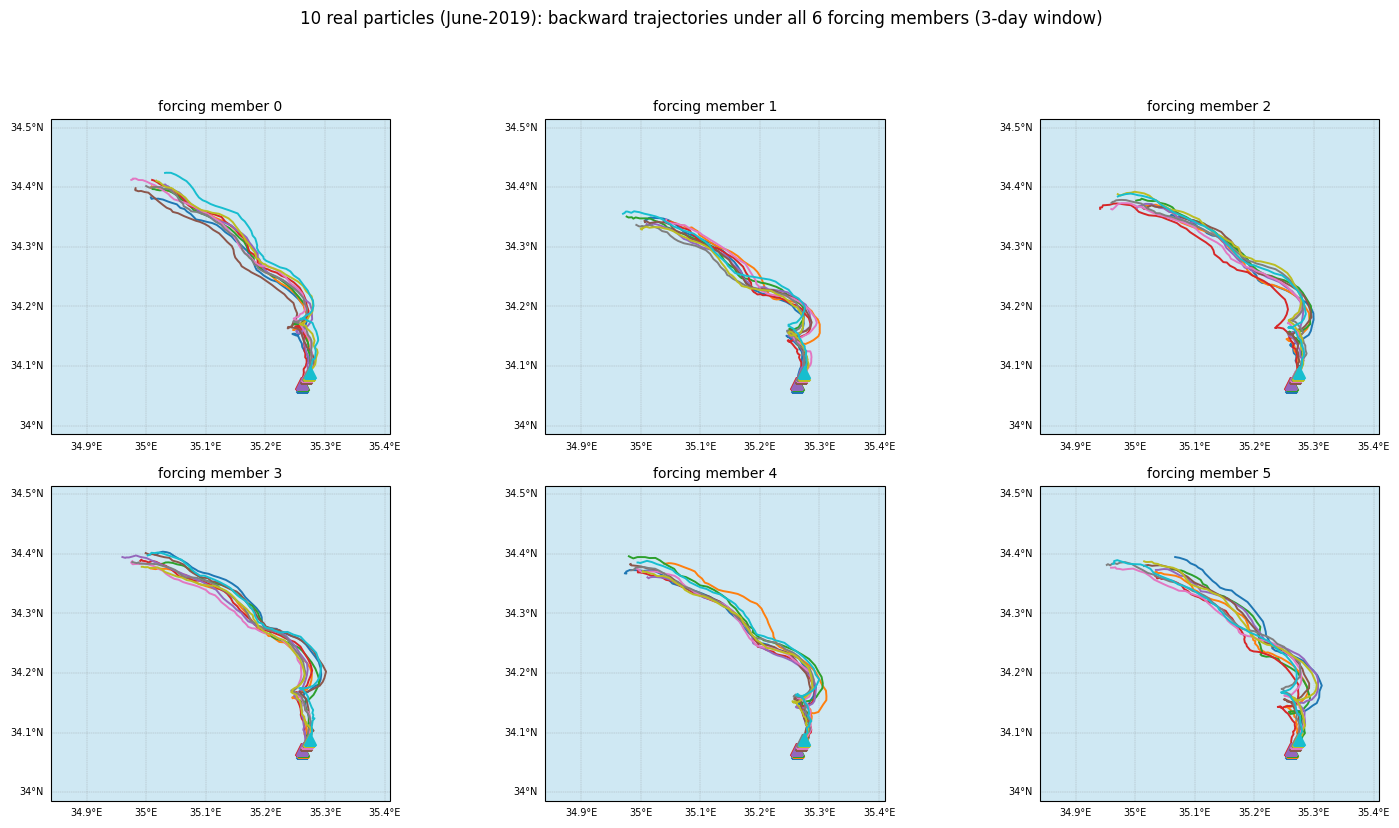

In [12]:
traj_multi = {pid: {} for pid in selected_10}
for pid in selected_10:
    for m in FORCING_MEMBER_IDS_USED:
        mask = (records.particle_id == pid) & (records.forcing_member_id == m)
        order = np.argsort(-records.timestamp[mask].astype("int64"))
        traj_multi[pid][m] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])

n_members = len(FORCING_MEMBER_IDS_USED)
ncols = 3
nrows = int(np.ceil(n_members / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows), subplot_kw={"projection": MAP_PROJECTION})
axes = np.atleast_1d(axes).ravel()
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_geographic_basemap(ax, ANIMATION_EXTENT)
    for pid, c in zip(selected_10, colors):
        tr = traj_multi[pid][m]
        ax.plot(tr["lon"], tr["lat"], "-", color=c, linewidth=1.4, transform=ccrs.PlateCarree(), zorder=5)
        ax.plot(tr["lon"][0], tr["lat"][0], "^", color=c, markersize=9, transform=ccrs.PlateCarree(), zorder=6)
    ax.set_title(f"forcing member {m}", fontsize=10)
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
fig.suptitle(f"10 real particles (June-2019): backward trajectories under all {n_members} forcing members (3-day window)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "07_multimember_static.png"), dpi=100), label="07_multimember_static.png")
plt.show()

### Multi-member backward-transport animation (10 real particles x 6 forcing members, June 2019)

Task 4 requirement 9: same evolving heatmap treatment, one instance per member
panel (all six draw from the SAME `support_grids_by_t_s[t_s]` -- the Support field
already pools all 6 forcing members at each timestamp, matching how T16 has always
computed it; only the drawn PARTICLE trajectory differs per panel).

In [13]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows), subplot_kw={"projection": MAP_PROJECTION})
axes = np.atleast_1d(axes).ravel()

lines_by_member = {}
points_by_member = {}
heatmap_by_member = {}
_initial_grid_mm = support_grids_by_t_s[float(checkpoints[-1])]
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_geographic_basemap(ax, ANIMATION_EXTENT)
    heatmap_by_member[m] = ax.pcolormesh(support_lon_grid, support_lat_grid, _initial_grid_mm, shading="auto", cmap="viridis", norm=display_norm(), transform=ccrs.PlateCarree(), zorder=3, alpha=0.85)
    ax.set_title(f"forcing member {m}", fontsize=10)
    lines_by_member[m] = [ax.plot([], [], "-", color=c, linewidth=1.4, transform=ccrs.PlateCarree(), zorder=5)[0] for c in colors]
    points_by_member[m] = [ax.plot([], [], "o", color=c, markersize=8, transform=ccrs.PlateCarree(), zorder=6)[0] for c in colors]
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
cb = fig.colorbar(heatmap_by_member[FORCING_MEMBER_IDS_USED[0]], ax=list(axes[:len(FORCING_MEMBER_IDS_USED)]), shrink=0.6, pad=0.02)
cb.set_label(DISPLAY_NORM_COLORBAR_LABEL, fontsize=6.5)
suptitle_mm = fig.suptitle("", fontsize=13)

def init_mm():
    artists = []
    for m in FORCING_MEMBER_IDS_USED:
        for l, p in zip(lines_by_member[m], points_by_member[m]):
            l.set_data([], []); p.set_data([], [])
            artists += [l, p]
        artists.append(heatmap_by_member[m])
    return artists

def update_mm(frame):
    artists = []
    t_now = traj_multi[selected_10[0]][FORCING_MEMBER_IDS_USED[0]]["t"][frame]
    grid_now = support_grids_by_t_s[float(np.datetime64(t_now, "ns"))]
    for m in FORCING_MEMBER_IDS_USED:
        for i, pid in enumerate(selected_10):
            tr = traj_multi[pid][m]
            lines_by_member[m][i].set_data(tr["lon"][:frame + 1], tr["lat"][:frame + 1])
            points_by_member[m][i].set_data([tr["lon"][frame]], [tr["lat"][frame]])
        heatmap_by_member[m].set_array(grid_now.ravel())
        artists += lines_by_member[m] + points_by_member[m] + [heatmap_by_member[m]]
    suptitle_mm.set_text(f"10 real particles (June-2019) backward under {n_members} forcing members -- t = {np.datetime64(t_now,'ns')}")
    return artists

anim_mm = animation.FuncAnimation(fig, update_mm, frames=n_frames, init_func=init_mm, blit=False, interval=200)
fig.tight_layout(rect=(0, 0, 1, 0.93))
mp4_path_mm = os.path.join(RESULTS_DIR, "08_multimember_animation.mp4")
gif_path_mm = os.path.join(RESULTS_DIR, "08_multimember_animation.gif")
save_animation_with_retry(anim_mm, mp4_path_mm, gif_path_mm, fps=6)
plt.close(fig)

C:\Users\venka\AppData\Local\Temp\ipykernel_42932\4086859639.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.93))


saved animation (MP4) to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\08_multimember_animation.mp4


project AOI (reference)   : N=36.372, W=27.121, S=30.1875, E=36.088
animation map extent (zoom): west=34.8395 east=35.4091 south=33.9850 north=34.5141
trajectory bbox            : lon [34.9195,35.3291]  lat [34.0650,34.4341]
no trajectory clipped (lon): True
no trajectory clipped (lat): True
trajectory occupies 71.9% of frame width, 69.8% of frame height


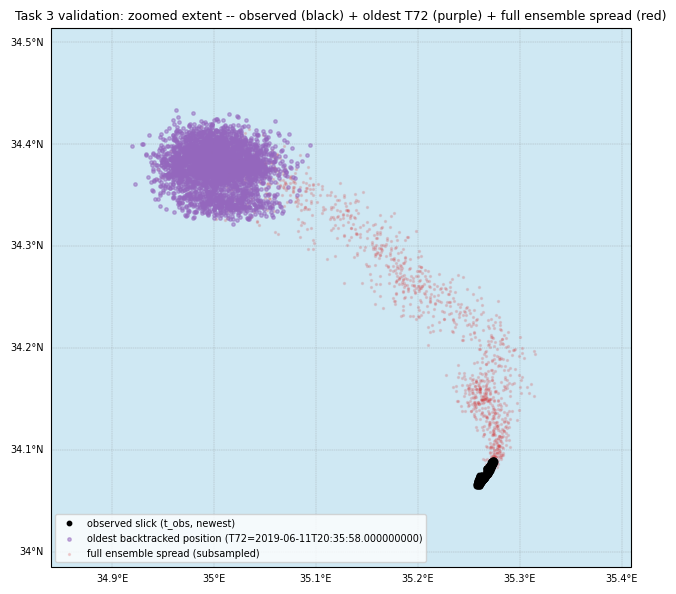

visual check: observed slick, oldest T72 positions, and the full ensemble spread must ALL be visible inside the frame (none clipped at the edges) -- confirm from validation_map_alignment.png


In [14]:
# --- Task 2/3 visual validation: zoomed extent, no clipping, coastline/particle alignment ---
print(f"project AOI (reference)   : N={AOI_NORTH}, W={AOI_WEST}, S={AOI_SOUTH}, E={AOI_EAST}")
print(f"animation map extent (zoom): west={ZOOM_WEST:.4f} east={ZOOM_EAST:.4f} south={ZOOM_SOUTH:.4f} north={ZOOM_NORTH:.4f}")
print(f"trajectory bbox            : lon [{TRAJ_LON_MIN:.4f},{TRAJ_LON_MAX:.4f}]  lat [{TRAJ_LAT_MIN:.4f},{TRAJ_LAT_MAX:.4f}]")

no_clip_lon = (TRAJ_LON_MIN >= ZOOM_WEST) and (TRAJ_LON_MAX <= ZOOM_EAST)
no_clip_lat = (TRAJ_LAT_MIN >= ZOOM_SOUTH) and (TRAJ_LAT_MAX <= ZOOM_NORTH)
print(f"no trajectory clipped (lon): {no_clip_lon}")
print(f"no trajectory clipped (lat): {no_clip_lat}")
assert no_clip_lon and no_clip_lat, "trajectory bbox exceeds the computed zoom extent -- margin too small!"

traj_frac_of_frame_lon = (TRAJ_LON_MAX - TRAJ_LON_MIN) / (ZOOM_EAST - ZOOM_WEST)
traj_frac_of_frame_lat = (TRAJ_LAT_MAX - TRAJ_LAT_MIN) / (ZOOM_NORTH - ZOOM_SOUTH)
print(f"trajectory occupies {traj_frac_of_frame_lon:.1%} of frame width, {traj_frac_of_frame_lat:.1%} of frame height")

fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": MAP_PROJECTION})
add_geographic_basemap(ax, ANIMATION_EXTENT)
ax.scatter(obs_lon, obs_lat, s=10, c="black", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (t_obs, newest)")
oldest_t = checkpoints[0]  # checkpoints = np.unique(records.timestamp), ascending -> [0] is T72 (oldest)
oldest_mask = records.timestamp == oldest_t
oldest_valid = oldest_mask & records.valid
ax.scatter(records.lon[oldest_valid], records.lat[oldest_valid], s=6, c="tab:purple", alpha=0.5, transform=ccrs.PlateCarree(), zorder=5, label=f"oldest backtracked position (T72={oldest_t})")
ax.scatter(records.lon[records.valid][::200], records.lat[records.valid][::200], s=2, alpha=0.15, c="tab:red", transform=ccrs.PlateCarree(), zorder=4, label="full ensemble spread (subsampled)")
ax.legend(fontsize=7, loc="lower left")
ax.set_title("Task 3 validation: zoomed extent -- observed (black) + oldest T72 (purple) + full ensemble spread (red)", fontsize=9)
fig.savefig(os.path.join(RESULTS_DIR, "validation_map_alignment.png"), dpi=100)
plt.show()
print("visual check: observed slick, oldest T72 positions, and the full ensemble spread must ALL be visible "
      "inside the frame (none clipped at the edges) -- confirm from validation_map_alignment.png")

### Hotspot visualization (June 2019) -- Task 4: display-normalized, T0/mid/T48/T72

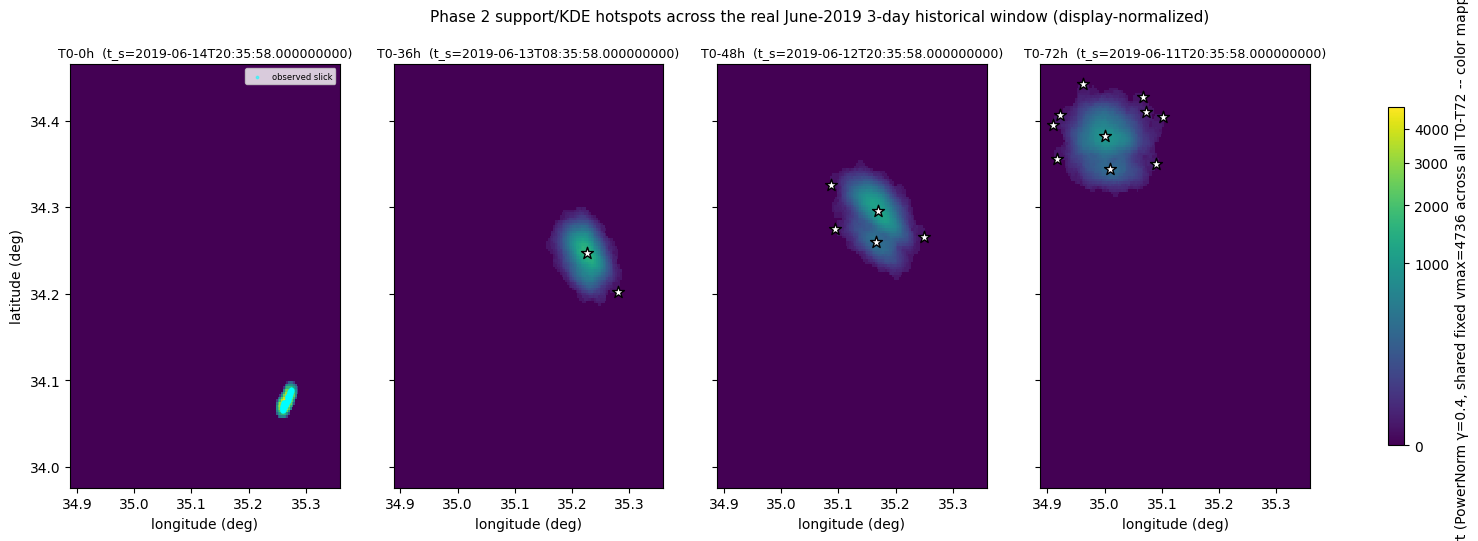

In [15]:
# Task 4 requirement 7: representative snapshots -- T0/recent, mid-window, T48, T72/oldest
snapshot_hours = [0, 36, 48, 72]
snapshot_t_s = [RUN_T_OBS - np.timedelta64(h, "h") for h in snapshot_hours]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), sharex=True, sharey=True)
top10_ids_preview = {c.candidate_id for c in sorted(all_candidates, key=lambda c: -c.support_score)[:10]}
for ax, h, t_s in zip(axes, snapshot_hours, snapshot_t_s):
    grid_vals = support_grids_by_t_s[float(t_s)]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", norm=display_norm())
    # keep scientific overlays (requirement 8): candidate markers + particle positions
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == np.datetime64(t_s, "ns")]
    for c in cands_here:
        is_top10 = c.candidate_id in top10_ids_preview
        ax.scatter([c.x_peak], [c.y_peak], marker="*", s=180 if is_top10 else 80,
                   c="red" if is_top10 else "white", edgecolors="black", linewidths=1, zorder=5)
    if h == 0:
        ax.scatter(obs_lon, obs_lat, s=3, c="cyan", alpha=0.5, zorder=4, label="observed slick")
        ax.legend(fontsize=6, loc="upper right")
    ax.set_title(f"T0-{h}h  (t_s={np.datetime64(t_s,'ns')})", fontsize=9)
    ax.set_xlabel("longitude (deg)")
axes[0].set_ylabel("latitude (deg)")
fig.colorbar(mesh, ax=axes, label=DISPLAY_NORM_COLORBAR_LABEL, shrink=0.8)
fig.suptitle("Phase 2 support/KDE hotspots across the real June-2019 3-day historical window (display-normalized)", fontsize=11)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "04_hotspot_heatmap.png"), dpi=100), label="04_hotspot_heatmap.png")
plt.show()

## 6. Monte Carlo particle density vs. T16 support/KDE heatmap (June 2019)

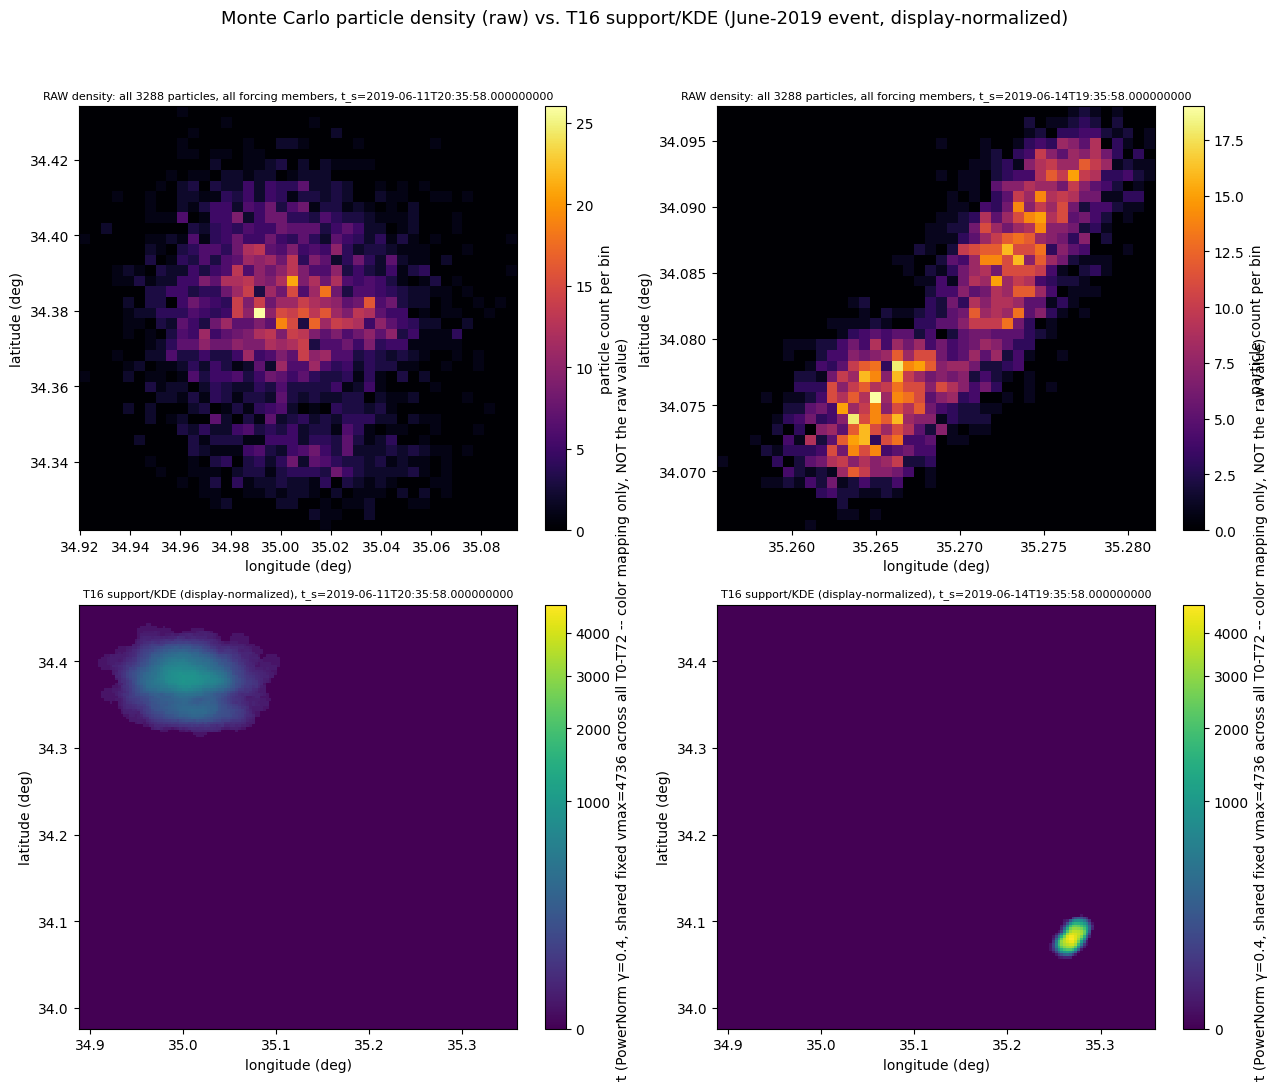

In [16]:
density_sample_t_s = [historical_timestamps[0], historical_timestamps[-1]]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, t_s in enumerate(density_sample_t_s):
    slice_ = query_particle_slice(records, t_s)
    vmask = slice_.valid
    lat_all, lon_all = slice_.lat[vmask], slice_.lon[vmask]
    n_points = len(lat_all)

    ax = axes[0, col]
    h = ax.hist2d(lon_all, lat_all, bins=40, cmap="inferno")
    fig.colorbar(h[3], ax=ax, label="particle count per bin")
    ax.set_title(f"RAW density: all {n_points} particles, all forcing members, t_s={np.datetime64(t_s,'ns')}", fontsize=8)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")

    support_grid = support_grids_by_t_s[float(t_s)]
    ax = axes[1, col]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, support_grid, shading="auto", cmap="viridis", norm=display_norm())
    fig.colorbar(mesh, ax=ax, label=DISPLAY_NORM_COLORBAR_LABEL)
    ax.set_title(f"T16 support/KDE (display-normalized), t_s={np.datetime64(t_s,'ns')}", fontsize=8)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")

fig.suptitle("Monte Carlo particle density (raw) vs. T16 support/KDE (June-2019 event, display-normalized)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "09_montecarlo_density.png"), dpi=100), label="09_montecarlo_density.png")
plt.show()

## 7. Select 10 hotspots for forward validation (June 2019)

In [17]:
top10_candidates = sorted(all_candidates, key=lambda c: -c.support_score)[:10]
top10_t_s = sorted({np.datetime64(c.t_s, "ns") for c in top10_candidates})
print(f"selected {len(top10_candidates)} of {len(all_candidates)} available candidates for forward validation")
print(f"spanning {len(top10_t_s)} distinct historical timestamps")
for c in top10_candidates:
    print(f"  {c.candidate_id:30s} {c.y_peak:9.4f} {c.x_peak:9.4f} {c.support_score:14.2f}")

selected 10 of 271 available candidates for forward validation
spanning 10 distinct historical timestamps
  2019-06-14T19:35:58_cand000      34.0795   35.2675        4735.69
  2019-06-14T18:35:58_cand000      34.0855   35.2705        4675.41
  2019-06-14T17:35:58_cand000      34.0915   35.2735        4571.86
  2019-06-14T16:35:58_cand000      34.0945   35.2765        4563.39
  2019-06-14T15:35:58_cand000      34.1005   35.2765        4393.76
  2019-06-14T14:35:58_cand000      34.1035   35.2765        4330.89
  2019-06-14T13:35:58_cand000      34.1095   35.2765        4250.76
  2019-06-14T12:35:58_cand000      34.1125   35.2765        4226.00
  2019-06-14T11:35:58_cand000      34.1185   35.2765        4124.95
  2019-06-14T10:35:58_cand000      34.1215   35.2735        4024.63


## 8. Forward propagation + predicted-vs-observed comparison (T18-T25, June 2019)

In [18]:
FOOTPRINT_BANDWIDTH_M = 400.0
phase2_config = Phase2RunConfig(
    historical_timestamps=tuple(top10_t_s), t_obs=RUN_T_OBS,
    support_query_lat_grid=support_lat_grid, support_query_lon_grid=support_lon_grid,
    neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, support_config=support_config,
    extraction_config=extraction_config, forward_budget_config=ForwardBudgetConfig(X=20),
    forcing_member_ids=FORCING_MEMBER_IDS_USED, forward_dt_seconds=3600.0,
    footprint_lat_grid=support_lat_grid, footprint_lon_grid=support_lon_grid,
    footprint_bandwidth_m=FOOTPRINT_BANDWIDTH_M,
    comparison_config=ComparisonConfig(metric="combined_overlap_fp"),
    screening_config=ScreeningConfig(mode="top_k", top_k=10, merge_separation_m=1500.0),
    master_seed=123,
)

t0 = time.time()
result = run_phase2_pipeline(records, ocean, ensemble, ocean.lat, ocean.lon, K, adapted, phase2_config)
t1 = time.time()
print(f"T18-T25 (integrated pipeline) took {t1 - t0:.1f}s")

found_ids = {c.candidate.candidate_id for ts in result.timestamps for c in ts.candidates}
top10_ids = {c.candidate_id for c in top10_candidates}
print(f"pipeline processed {len(found_ids)} candidates; matches selection exactly: {found_ids == top10_ids}")
assert found_ids == top10_ids

for dcn in sorted(result.decisions, key=lambda x: (x.rank is None, x.rank if x.rank else 0)):
    print(f"  {dcn.record.candidate_id}  accepted={dcn.accepted}  rank={dcn.rank}  "
          f"error={dcn.record.candidate_forward_error}  reason={dcn.rejection_reason}")

T18-T25 (integrated pipeline) took 27.1s
pipeline processed 10 candidates; matches selection exactly: True
  2019-06-14T19:35:58_cand000  accepted=True  rank=1  error=0.2095369979429047  reason=
  2019-06-14T17:35:58_cand000  accepted=True  rank=2  error=0.2811356521396089  reason=
  2019-06-14T18:35:58_cand000  accepted=True  rank=3  error=0.29541939568760284  reason=
  2019-06-14T16:35:58_cand000  accepted=True  rank=4  error=0.29594145804898425  reason=
  2019-06-14T14:35:58_cand000  accepted=True  rank=5  error=0.34148512616210724  reason=
  2019-06-14T15:35:58_cand000  accepted=True  rank=6  error=0.3501521803481538  reason=
  2019-06-14T13:35:58_cand000  accepted=True  rank=7  error=0.3724089108482363  reason=
  2019-06-14T12:35:58_cand000  accepted=True  rank=8  error=0.3837630872562012  reason=
  2019-06-14T10:35:58_cand000  accepted=True  rank=9  error=0.4622180876176614  reason=
  2019-06-14T11:35:58_cand000  accepted=True  rank=10  error=0.463080872844343  reason=


### Predicted vs. observed: best- and worst-ranked (June 2019)

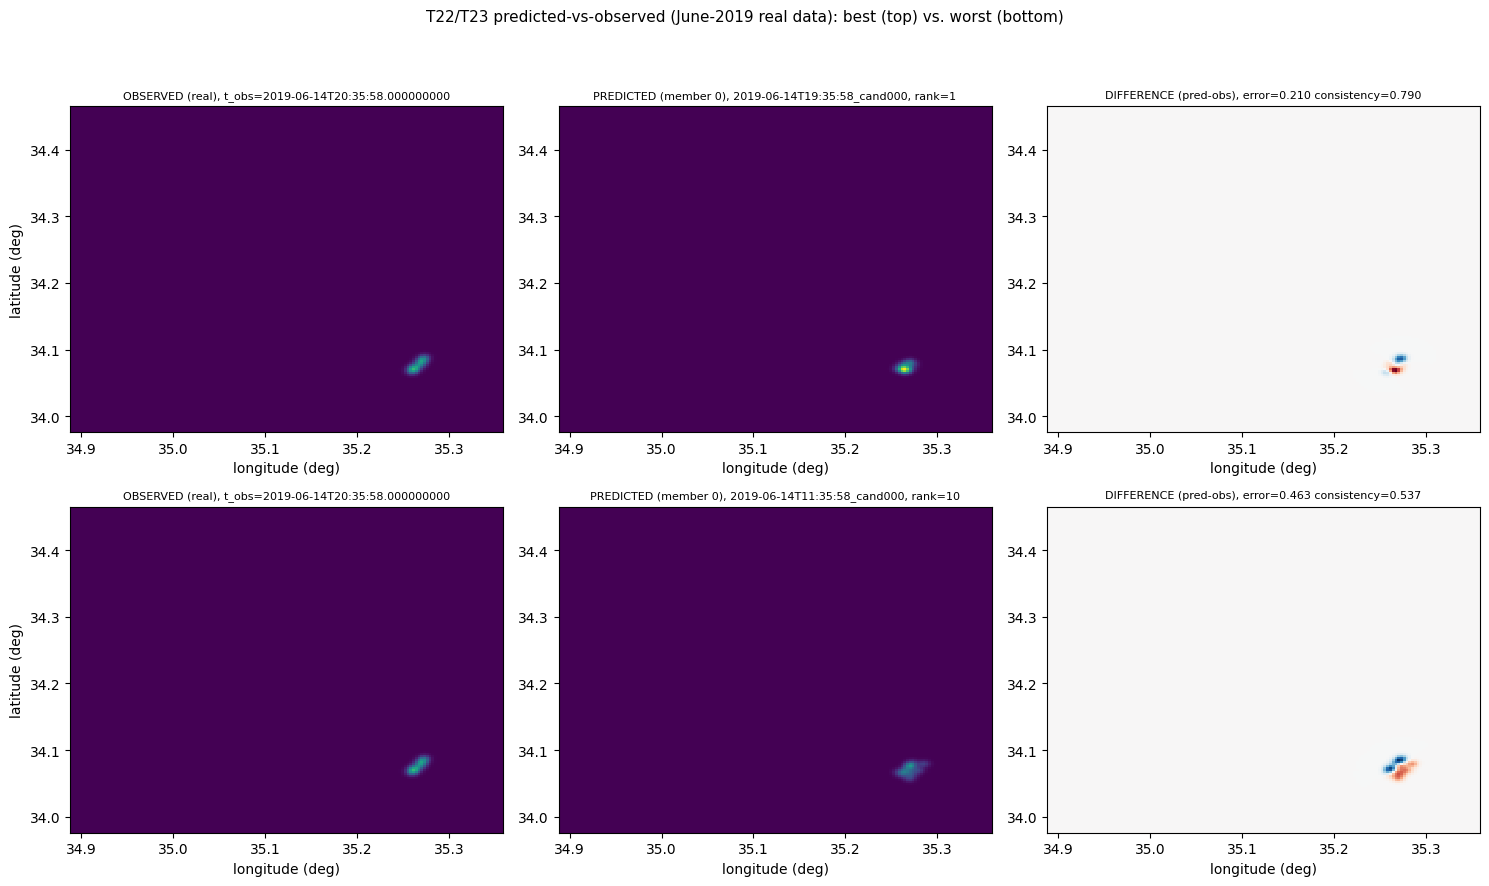

best: 2019-06-14T19:35:58_cand000 rank=1 error=0.2095
worst: 2019-06-14T11:35:58_cand000 rank=10 error=0.4631


In [19]:
def find_pipeline_candidate(cand_id):
    for ts in result.timestamps:
        for c in ts.candidates:
            if c.candidate.candidate_id == cand_id:
                return c
    return None

by_rank = sorted([d for d in result.decisions if d.accepted], key=lambda d: d.rank)
best, worst = by_rank[0], by_rank[-1]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
vmax2 = max(np.nanmax(result.observed_footprint.density),
            *[np.nanmax(find_pipeline_candidate(d.record.candidate_id).predicted_footprints[0].density) for d in [best, worst]])
for row, dcn in enumerate([best, worst]):
    c = find_pipeline_candidate(dcn.record.candidate_id)
    axes[row, 0].pcolormesh(support_lon_grid, support_lat_grid, result.observed_footprint.density, shading="auto", cmap="viridis", vmin=0, vmax=vmax2)
    axes[row, 0].set_title(f"OBSERVED (real), t_obs={RUN_T_OBS}", fontsize=8)
    axes[row, 1].pcolormesh(support_lon_grid, support_lat_grid, c.predicted_footprints[0].density, shading="auto", cmap="viridis", vmin=0, vmax=vmax2)
    axes[row, 1].set_title(f"PREDICTED (member 0), {dcn.record.candidate_id}, rank={dcn.rank}", fontsize=8)
    diff = c.predicted_footprints[0].density - result.observed_footprint.density
    lim = np.nanmax(np.abs(diff))
    axes[row, 2].pcolormesh(support_lon_grid, support_lat_grid, diff, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[row, 2].set_title(f"DIFFERENCE (pred-obs), error={dcn.record.candidate_forward_error:.3f} consistency={dcn.record.candidate_forward_consistency:.3f}", fontsize=8)
    for ax in axes[row]:
        ax.set_xlabel("longitude (deg)")
    axes[row, 0].set_ylabel("latitude (deg)")
fig.suptitle("T22/T23 predicted-vs-observed (June-2019 real data): best (top) vs. worst (bottom)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "05_predicted_vs_observed.png"), dpi=100), label="05_predicted_vs_observed.png")
plt.show()
print(f"best: {best.record.candidate_id} rank={best.rank} error={best.record.candidate_forward_error:.4f}")
print(f"worst: {worst.record.candidate_id} rank={worst.rank} error={worst.record.candidate_forward_error:.4f}")

## 9. Final top-10 candidate details (T24/T25, June 2019)

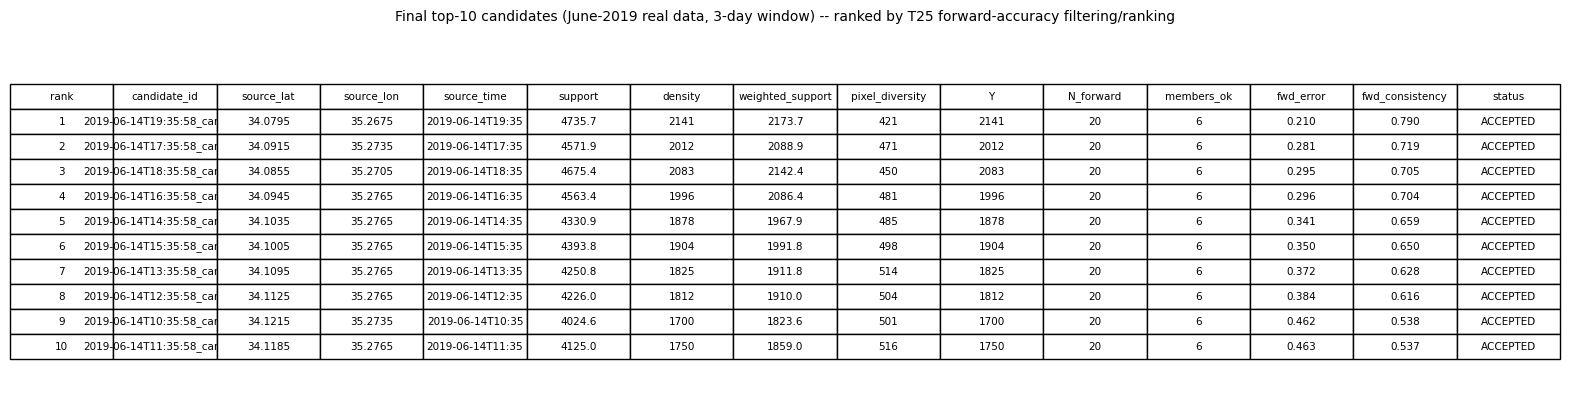

In [20]:
ranked_decisions = sorted(result.decisions, key=lambda d: (d.rank is None, d.rank if d.rank is not None else 0))
col_labels = ["rank", "candidate_id", "source_lat", "source_lon", "source_time", "support", "density",
              "weighted_support", "pixel_diversity", "Y", "N_forward", "members_ok", "fwd_error", "fwd_consistency", "status"]
rows = []
for dcn in ranked_decisions:
    r = dcn.record
    rows.append([
        dcn.rank if dcn.rank else "-", r.candidate_id, f"{r.y_peak:.4f}", f"{r.x_peak:.4f}",
        str(r.t_s)[:16], f"{r.support_score:.1f}", f"{r.density_score:.0f}",
        f"{r.weighted_support_score:.1f}", f"{r.pixel_diversity_score:.0f}",
        r.core_particle_count_Y, r.forward_particle_count_N_forward, len(r.forcing_members_validated),
        f"{r.candidate_forward_error:.3f}" if r.forward_validation_status == "validated" else "n/a",
        f"{r.candidate_forward_consistency:.3f}" if r.forward_validation_status == "validated" else "n/a",
        "ACCEPTED" if dcn.accepted else f"rejected: {dcn.rejection_reason[:30]}",
    ])

fig, ax = plt.subplots(figsize=(20, 0.5 + 0.4 * len(rows)))
ax.axis("off")
table = ax.table(cellText=rows, colLabels=col_labels, loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(7.5); table.scale(1, 1.5)
ax.set_title(f"Final top-{len(rows)} candidates (June-2019 real data, 3-day window) -- ranked by T25 forward-accuracy filtering/ranking", fontsize=10, pad=20)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "06_final_top10_table.png"), dpi=110, bbox_inches="tight"), label="06_final_top10_table.png")
plt.show()

In [21]:
artifact_path = os.path.join(RESULTS_DIR, "final_top10_candidates.json")
save_with_retry(lambda: save_phase2_artifact(result.decisions, phase2_config, artifact_path), label="final_top10_candidates.json")
with open(artifact_path, "r", encoding="utf-8") as f:
    reloaded_artifact = json.load(f)
print(f"saved + verified final machine-readable artifact: {artifact_path} ({len(reloaded_artifact['candidates'])} candidates)")

saved + verified final machine-readable artifact: C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\final_top10_candidates.json (10 candidates)


## 10. Validation

In [22]:
checks = []
checks.append(("RUN_T_OBS equals the TRUE June-2019 observation timestamp (no workaround)", RUN_T_OBS == TRUE_OBS_TIMESTAMP))
checks.append(("73 checkpoints present", len(checkpoints) == 73))
checks.append(("no October timestamps anywhere", not any(str(t)[:7] == "2019-10" for t in checkpoints)))
checks.append(("forward-validation pipeline processed exactly the selected 10 candidates", found_ids == top10_ids))
checks.append(("final artifact round-trips", len(reloaded_artifact["candidates"]) == len(result.decisions)))
checks.append(("support_grids_by_t_s covers all 73 T0-T72 timestamps", len(support_grids_by_t_s) == 73))
checks.append(("display normalization uses ONE fixed global vmax (not per-frame)", isinstance(GLOBAL_SUPPORT_VMAX, float)))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(os.listdir(RESULTS_DIR))
print(f"{len(output_files)} files now saved under {RESULTS_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] RUN_T_OBS equals the TRUE June-2019 observation timestamp (no workaround)
[OK] 73 checkpoints present
[OK] no October timestamps anywhere
[OK] forward-validation pipeline processed exactly the selected 10 candidates
[OK] final artifact round-trips
[OK] support_grids_by_t_s covers all 73 T0-T72 timestamps
[OK] display normalization uses ONE fixed global vmax (not per-frame)
46 files now saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  01_observation.png  (110.5 KB)
  02_backward_trajectories_10particles.png  (71.7 KB)
  03_backward_animation.mp4  (104.6 KB)
  04_hotspot_heatmap.png  (68.7 KB)
  05_predicted_vs_observed.png  (58.2 KB)
  06_final_top10_table.png  (77.7 KB)
  07_multimember_static.png  (168.5 KB)
  08_multimember_animation.mp4  (352.9 KB)
  09_montecarlo_density.png  (102.8 KB)
  T28_diagnostics_t0_t72.png  (88.9 KB)
  T29_raw_vs_normalized_kde.png  (77.4 KB)
  T30_initial_bias_influence.png  (46.1 KB)
  T31_displacement_distribution.png  (22.